In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [4]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and w<1')

In [5]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

Process PYTHIA6+GEANT

In [6]:
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')

In [7]:
print(df_match.shape[0], df_allfake.shape[0])

2623349 1471810


In [8]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)] ]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [9]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [11]:
plt.rcParams['font.size'] = 12

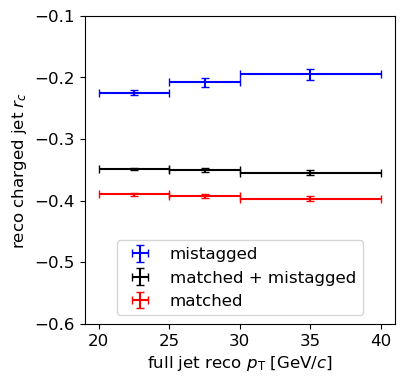

In [13]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:-1], capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([22.5, 27.5, 35], rc_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')

In [14]:
rc_allfake_bs_vs_pts_array

[-0.2381035133227144,
 -0.22484396308404456,
 -0.20816523320893293,
 -0.19538699336733573,
 -0.1801381876050286]

In [15]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [16]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [17]:
b_fake_array

[array([0.61905176, 0.38094824]),
 array([0.61242198, 0.38757802]),
 array([0.60408262, 0.39591738]),
 array([0.5976935, 0.4023065]),
 array([0.59006909, 0.40993091])]

In [18]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [19]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

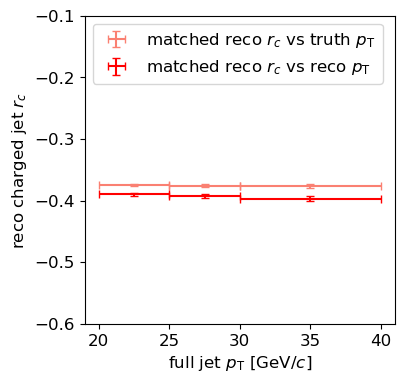

In [20]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco $r_c$ vs truth $p_{\mathrm{T}}$')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco $r_c$ vs reco $p_{\mathrm{T}}$')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left')

In [21]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.69613888 0.30386112]
[0.69480417 0.30519583]
[0.69601126 0.30398874]
[0.69844548 0.30155452]
[0.69854114 0.30145886]


In [22]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_2753869/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [23]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.29936704, 0.24871283, 0.22295968, 0.20754411, 0.19886014])

In [56]:
match_fake, x = calc_hist(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[df_allreco.pt!=-9]['pts'], bins=binedges, weights=df_allreco[df_allreco.pt!=-9]['ws'])
eff2 = match/match_fake

/tmp/ipykernel_2753869/422490013.py:3: RuntimeWarning: invalid value encountered in divide
  eff2 = match/match_fake


In [57]:
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9)]['ws'])
eff3 = match/match_fake

/tmp/ipykernel_2753869/2198547993.py:3: RuntimeWarning: invalid value encountered in divide
  eff3 = match/match_fake


In [58]:
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_2753869/1314457487.py:3: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


(0.0, 1.0)

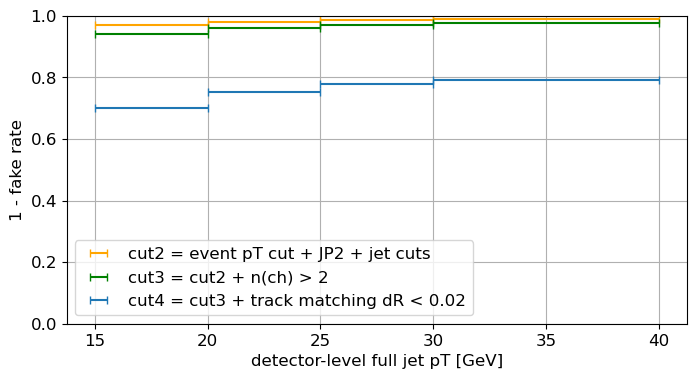

In [61]:
plt.figure(figsize=(4,4))
bincenters=[7.5, 12.5,17.5,22.5,27.5,35,50]
plt.errorbar(bincenters[2:6], eff2[2:6], xerr=[2.5,2.5,2.5,5], label='cut 1 = ', color='orange', ls='none', capsize=3)
plt.errorbar(bincenters[2:6], eff3[2:6], xerr=[2.5,2.5,2.5,5], label='cut3 = cut2 + n(ch) > 2', color='g', ls='none', capsize=3)
plt.errorbar(bincenters[2:6], eff4[2:6], xerr=[2.5,2.5,2.5,5], label='cut4 = cut3 + track matching dR < 0.02', ls='none', capsize=3)
plt.xlabel('detector-level full jet pT [GeV]')
plt.ylabel('matched fraction')
plt.legend()
plt.ylim(0.,1)

In [63]:
print(eff4[2:6]+fake_rate_array[:-1])

[1. 1. 1. 1.]


Process data

In [26]:
observables1 = ['pt','m','q2','rg','zg','mg','b']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [27]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [28]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [29]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [30]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

In [31]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [32]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[241787.4194556  119359.44336324]
[491.71884188 345.48436052]
1
[72379. 38554.]
[55481.99560278 27860.54405046]
[235.54616448 166.9147808 ]
2
[16450.  8688.]
[13064.26158427  6468.97787029]
[114.2990008  80.4299563]
3
[4758. 2573.]
[3848.60584569 1960.88829996]
[62.0371328  44.28191843]
4
[334. 153.]
[276.85482568 113.30028798]
[16.63895507 10.6442608 ]


In [33]:
reweight_array = []
for i in range(0,5):
    reweight = (b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i]))/(b_match_array[i]/sum(b_match_array[i]))
    reweight_array.append(reweight)

In [34]:
reweight_array

[array([0.96173177, 1.08767165]),
 array([0.95812666, 1.09532821]),
 array([0.9609357 , 1.08944143]),
 array([0.94848967, 1.11930564]),
 array([1.01583414, 0.96330909])]

In [35]:
b_data_array[1][0]

72379.0

([], [])

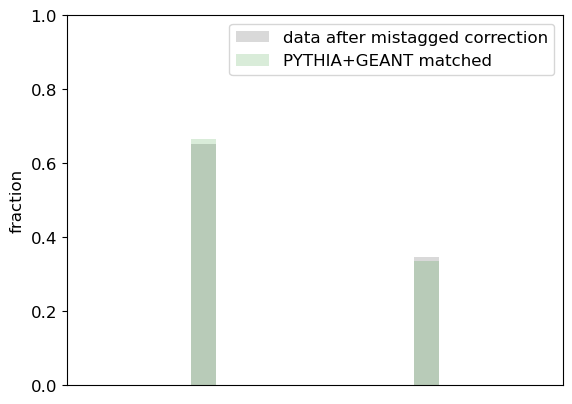

In [36]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

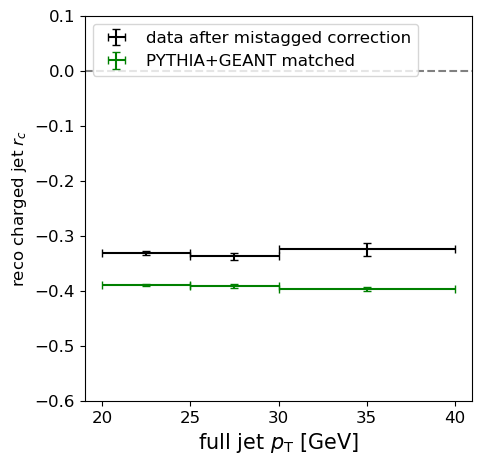

In [37]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc1_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc1_err_array[1:-1], capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

Reweight PYTHIA6+GEANT

In [38]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 64.71016459194377
anomaly reco pT: 60.153276062896694
anomaly reco pT: 62.853705443277754
anomaly reco pT: 62.96298659444578
anomaly reco pT: 60.497728730756755
anomaly reco pT: 60.467066272681684
anomaly reco pT: 64.14492779876475
anomaly reco pT: 60.89421353610575
anomaly reco pT: 65.35667922469173
anomaly reco pT: 62.63427678982773
anomaly reco pT: 60.21434194892271
anomaly reco pT: 62.15032283200955
anomaly reco pT: 60.27780299483247
anomaly reco pT: 61.03197986884235
anomaly reco pT: 60.25483540234041
anomaly reco pT: 63.99508646678217
anomaly reco pT: 61.56890722000404
anomaly reco pT: 60.8697641572812
anomaly reco pT: 64.23631221912824
anomaly reco pT: 63.19369788337173
anomaly reco pT: 60.96653998630141
anomaly reco pT: 62.746029305931756
anomaly reco pT: 65.45530859825888
anomaly reco pT: 60.03476303183356
anomaly reco pT: 63.085829497123754
anomaly reco pT: 66.83963074901102
anomaly reco pT: 61.03609940388197
anomaly reco pT: 70.61911542903617
anomaly reco pT

anomaly reco pT: 61.37885697371845
anomaly reco pT: 61.45938905164215
anomaly reco pT: 60.16641125403288
anomaly reco pT: 60.09958144920835
anomaly reco pT: 60.511466054485055
anomaly reco pT: 62.350066426895815
anomaly reco pT: 66.11940247976565
anomaly reco pT: 62.15143279465398
anomaly reco pT: 60.697240773348895
anomaly reco pT: 61.79922547972766
anomaly reco pT: 62.11664288908429
anomaly reco pT: 66.38356449440559
anomaly reco pT: 70.6974465514885
anomaly reco pT: 62.49202362716819
anomaly reco pT: 61.065188221162096
anomaly reco pT: 61.23578848561933
anomaly reco pT: 61.52889434809697
anomaly reco pT: 60.31175466428895
anomaly reco pT: 63.22603510311757
anomaly reco pT: 60.18760080128897
anomaly reco pT: 62.83126138185055
anomaly reco pT: 61.152388176492224
anomaly reco pT: 63.75458910527901
anomaly reco pT: 68.07779701999323
anomaly reco pT: 60.92194379917718
anomaly reco pT: 60.93417972296193
anomaly reco pT: 61.33390390171952
anomaly reco pT: 61.446439875350215
anomaly reco pT

anomaly reco pT: 60.100454882871034
anomaly reco pT: 62.12533305728589
anomaly reco pT: 63.18755753863549
anomaly reco pT: 60.55812705404159
anomaly reco pT: 61.28085631237634
anomaly reco pT: 61.477432875243345
anomaly reco pT: 60.488095763928925
anomaly reco pT: 68.54885901919411
anomaly reco pT: 61.50396984848846
anomaly reco pT: 64.2182142798535
anomaly reco pT: 69.73367420432969
anomaly reco pT: 61.027595087508125
anomaly reco pT: 69.64749622782676
anomaly reco pT: 60.80583130708745
anomaly reco pT: 63.75691841415262
anomaly reco pT: 62.728856238000006
anomaly reco pT: 61.422837501199396
anomaly reco pT: 63.19510727748455
anomaly reco pT: 69.17229053514693
anomaly reco pT: 63.03810647468715
anomaly reco pT: 65.11635047674382
anomaly reco pT: 62.7859012143824
anomaly reco pT: 62.68461884512906
anomaly reco pT: 62.915869267031155
anomaly reco pT: 66.29737410911332
anomaly reco pT: 63.565336097220666
anomaly reco pT: 63.24551244561167
anomaly reco pT: 63.80560504086096
anomaly reco p

anomaly reco pT: 65.25033525577705
anomaly reco pT: 61.76350377269977
anomaly reco pT: 67.91261516206957
anomaly reco pT: 64.18896871067179
anomaly reco pT: 61.55566986656164
anomaly reco pT: 61.013202658559315
anomaly reco pT: 66.46683297420948
anomaly reco pT: 60.719874837864914
anomaly reco pT: 63.323007001359706
anomaly reco pT: 61.75751789795584
anomaly reco pT: 65.47874514245692
anomaly reco pT: 63.833226056318395
anomaly reco pT: 65.86571741812644
anomaly reco pT: 61.25108554868977
anomaly reco pT: 61.947579640882736
anomaly reco pT: 63.46254812809013
anomaly reco pT: 62.96891790372958
anomaly reco pT: 64.35138414682795
anomaly reco pT: 64.48172194800236
anomaly reco pT: 61.26632928367613
anomaly reco pT: 63.2261305431496
anomaly reco pT: 61.77634558122546
anomaly reco pT: 60.86607307973257
anomaly reco pT: 60.21395499719272
anomaly reco pT: 60.09408616047344
anomaly reco pT: 60.99685047564388
anomaly reco pT: 60.16363338769977
anomaly reco pT: 63.69926317750572
anomaly reco pT:

anomaly reco pT: 61.14995283043609
anomaly reco pT: 66.04902795304733
anomaly reco pT: 60.9882253190428
anomaly reco pT: 66.7477555786966
anomaly reco pT: 61.708920284156285
anomaly reco pT: 64.36438487503408
anomaly reco pT: 62.94062266284301
anomaly reco pT: 62.44423781464371
anomaly reco pT: 75.46724224373281
anomaly reco pT: 61.80903146481187
anomaly reco pT: 62.13383225030382
anomaly reco pT: 66.75514905802402
anomaly reco pT: 66.14452877031708
anomaly reco pT: 63.09405627123977
anomaly reco pT: 64.90408598375983
anomaly reco pT: 63.48728395117119
anomaly reco pT: 61.28346182911763
anomaly reco pT: 66.20971847276358
anomaly reco pT: 60.79420789744857
anomaly reco pT: 61.510335938526346
anomaly reco pT: 63.60463563764089
anomaly reco pT: 62.73743231404073
anomaly reco pT: 65.7725494015351
anomaly reco pT: 63.11734403019368
anomaly reco pT: 63.84290622372178
anomaly reco pT: 60.24441190326755
anomaly reco pT: 61.21301777980847
anomaly reco pT: 70.52696926518031
anomaly reco pT: 60.0

anomaly reco pT: 62.033255571884375
anomaly reco pT: 64.2315669762808
anomaly reco pT: 65.90115509233549
anomaly reco pT: 62.01507656506754
anomaly reco pT: 64.34097510153335
anomaly reco pT: 66.61530082068789
anomaly reco pT: 63.67323508181137
anomaly reco pT: 62.32187202592208
anomaly reco pT: 67.88504705434883
anomaly reco pT: 71.60937468564357
anomaly reco pT: 60.559015970087586
anomaly reco pT: 60.95447512822861
anomaly reco pT: 61.792050719662605
anomaly reco pT: 63.839684969398476
anomaly reco pT: 70.22762010076262
anomaly reco pT: 60.52819963422777
anomaly reco pT: 60.36284099980931
anomaly reco pT: 61.136199051860096
anomaly reco pT: 60.40803714967254
anomaly reco pT: 61.98943265829271
anomaly reco pT: 60.14072676847585
anomaly reco pT: 63.024973501665386
anomaly reco pT: 60.0567265490732
anomaly reco pT: 64.18815491158762
anomaly reco pT: 61.29028912670281
anomaly reco pT: 66.1197452494242
anomaly reco pT: 60.01477676891959
anomaly reco pT: 61.1943075724957
anomaly reco pT: 6

... (42 outputs left out)

anomaly reco pT: 66.25499377435676
anomaly reco pT: 62.603617878534024
anomaly reco pT: 60.460043739529105
anomaly reco pT: 60.83049730617721
anomaly reco pT: 65.37355169938866
anomaly reco pT: 69.59518219395216
anomaly reco pT: 60.359234653466515
anomaly reco pT: 61.99753803384197
anomaly reco pT: 74.74062825974873
anomaly reco pT: 61.231870219754185
anomaly reco pT: 61.34810138746052
anomaly reco pT: 63.906995773704566
anomaly reco pT: 63.47938797902859
anomaly reco pT: 61.84927450588027
anomaly reco pT: 66.7354770452589
anomaly reco pT: 60.496907211519904
anomaly reco pT: 61.04320124984645
anomaly reco pT: 68.39983380314385
anomaly reco pT: 61.97441309797338
anomaly reco pT: 61.63176769228725
anomaly reco pT: 65.0781164849145
anomaly reco pT: 61.88619547607164
anomaly reco pT: 67.12441359053437
anomaly reco pT: 71.81015635657576
anomaly reco pT: 64.68798391880726
anomaly reco pT: 60.07010372841588
anomaly reco pT: 61.3200915807578
anomaly reco pT: 63.317773956784976
anomaly reco pT:

anomaly reco pT: 69.1618255253066
anomaly reco pT: 66.45070512482627
anomaly reco pT: 64.04050174014357
anomaly reco pT: 65.7929565225058
anomaly reco pT: 61.42561900355657
anomaly reco pT: 64.03292334513661
anomaly reco pT: 62.72305902639425
anomaly reco pT: 65.49422360739337
anomaly reco pT: 60.274249788939414
anomaly reco pT: 67.22729453988428
anomaly reco pT: 60.32858078889216
anomaly reco pT: 60.82205350147582
anomaly reco pT: 60.04119196752329
anomaly reco pT: 64.47727309036974
anomaly reco pT: 64.62206824734714
anomaly reco pT: 60.46656574446182
anomaly reco pT: 61.285313715124275
anomaly reco pT: 61.901090291712286
anomaly reco pT: 64.19548711153159
anomaly reco pT: 63.60277263479115
anomaly reco pT: 60.88958171186299
anomaly reco pT: 66.7452749265485
anomaly reco pT: 62.796511155668064
anomaly reco pT: 62.86293580355628
anomaly reco pT: 62.74325096655931
anomaly reco pT: 60.26905338747298
anomaly reco pT: 62.97918714158118
anomaly reco pT: 63.34239460532443
anomaly reco pT: 60

anomaly reco pT: 61.05383916710107
anomaly reco pT: 60.42660842568787
anomaly reco pT: 61.14322146367162
anomaly reco pT: 60.061552181976346
anomaly reco pT: 64.92165043240804
anomaly reco pT: 60.34388086121147
anomaly reco pT: 61.78016981679419
anomaly reco pT: 67.87729945312982
anomaly reco pT: 66.89217697905926
anomaly reco pT: 63.75573034715998
anomaly reco pT: 60.54656062801299
anomaly reco pT: 66.78060904112989
anomaly reco pT: 70.08645529869048
anomaly reco pT: 65.41630438726278
anomaly reco pT: 65.67231186233347
anomaly reco pT: 62.85330310754562
anomaly reco pT: 64.77435274832786
anomaly reco pT: 64.08450866571178
anomaly reco pT: 61.04290523353271
anomaly reco pT: 60.16778329775381
anomaly reco pT: 60.275632493525265
anomaly reco pT: 60.05982937244574
anomaly reco pT: 60.336305610165375
anomaly reco pT: 62.075689213604285
anomaly reco pT: 60.54030969315109
anomaly reco pT: 60.03839792252459
anomaly reco pT: 62.85091547665885
anomaly reco pT: 60.62829967379875
anomaly reco pT:

/tmp/ipykernel_2753869/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [42]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [43]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

In [44]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array_rw = []
rc_err_match_bs_vs_pts_array_rw = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

Check that the reweighted embedding is the same as data

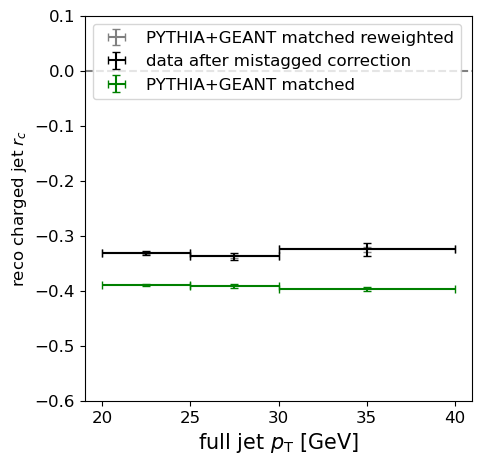

In [46]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array_rw[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array_rw[1:], capsize=3, color='grey', ls='none', label='PYTHIA+GEANT matched reweighted')
plt.errorbar([22.5, 27.5, 35], rc1_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc1_err_array[1:-1], capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

Plot result

(-0.6, 0.1)

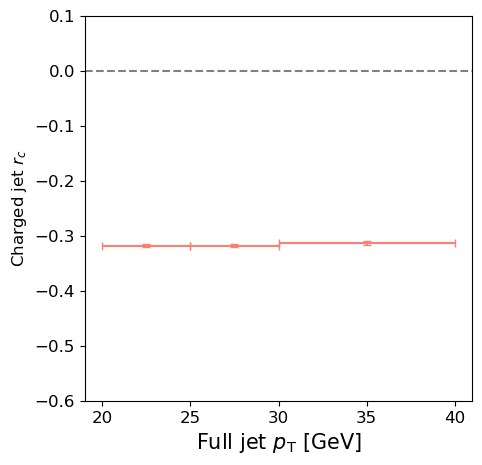

In [45]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [47]:
rc_match_bs_vs_pt_array

[-0.33622571385491123,
 -0.3181882812033977,
 -0.31823930777900206,
 -0.3135702652762947]

In [48]:
rc_err_match_bs_vs_pt_array

[0.0029097490942195815,
 0.002264048030301499,
 0.002823479322146174,
 0.0035104320098679194]

Check efficiency correction is not needed

In [42]:
df_alltruth = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_final.root', "MatchedTree"),\
              'pt>15 and b!=-9 and reject<=0 and rejects<=0')

In [43]:
df_alltruth_pt_array = [ df_alltruth[(df_alltruth.pt>15) & (df_alltruth.pt<20)],\
                       df_alltruth[(df_alltruth.pt>20) & (df_alltruth.pt<25)],\
                       df_alltruth[(df_alltruth.pt>25) & (df_alltruth.pt<30)],\
                       df_alltruth[(df_alltruth.pt>30) & (df_alltruth.pt<40)] ]

In [44]:
rc_alltruth_b_vs_pt_array = []
rc_err_alltruth_b_vs_pt_array = []
for i in range(0, len(df_alltruth_pt_array)):
    rc_alltruth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[0])
    rc_err_alltruth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[1])

In [45]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

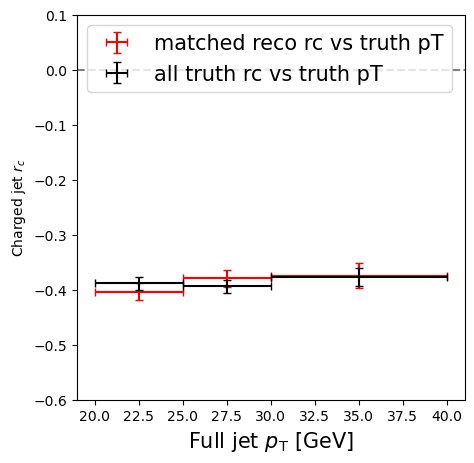

In [46]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='r', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_alltruth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_alltruth_b_vs_pt_array[1:], capsize=3, color='k', ls='none', label='all truth rc vs truth pT')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left', fontsize=15)